# J20 open field: example notebook

This notebook loads the NWB files converted from the Palop Lab J20-FVB open-field experiment and shows
how to work with them. hAPP-J20 transgenic (WT/TG) and wild-type (WT/WT) mice were each filmed from
above for 60 minutes in a circular open-field arena, on two exposures about one week apart. Eleven body
parts were tracked in every video with DeepLabCut.

Each NWB file holds one session: subject and session metadata, a reference to the session video, the
DeepLabCut pose estimates (ndx-pose), and, for 30 sessions, the hand-labeled training frames.

This notebook reads local NWB files. Set `nwb_dir_path` to the folder that holds them.

In [1]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import ndx_pose  # noqa: F401
import numpy as np
import pandas as pd
from pynwb import NWBHDF5IO

In [2]:
nwb_dir_path = Path("~/conversion_nwb/palop-lab-to-nwb").expanduser()
nwb_file_path = nwb_dir_path / "sub-63_ses-MetaSession3.nwb"

likelihood_threshold = 0.6
body_center = "Pelvis"

## Load a single session

In [3]:
io = NWBHDF5IO(nwb_file_path, "r")
nwbfile = io.read()

subject = nwbfile.subject
pd.Series(
    dict(
        session_id=nwbfile.session_id,
        session_start_time=nwbfile.session_start_time,
        session_description=nwbfile.session_description,
        notes=nwbfile.notes,
        subject_id=subject.subject_id,
        sex=subject.sex,
        genotype=subject.genotype,
        strain=subject.strain,
        age=subject.age,
        weight=subject.weight,
    )
).to_frame("value")

,value
session_id,MetaSession3
session_start_time,2024-01-16 09:47:53-08:00
session_description,"60-minute open-field session, exposure 1 of 2,..."
notes,weird ear marking right in the middle of the e...
subject_id,63
sex,F
genotype,hAPP-J20 WT/TG
strain,FVB
age,P91D
weight,25 g


The data streams live in two places: the video in `acquisition`, and the pose estimates, skeleton and
training frames in the `behavior` processing module.

In [4]:
print("acquisition:", list(nwbfile.acquisition))
print("behavior:", list(nwbfile.processing["behavior"].data_interfaces))

acquisition: ['BehaviorVideo']
behavior: ['PoseEstimationDeepLabCut', 'PoseTraining', 'Skeletons']


Each stream has its own review notebook with more detail and checks against the source files:

- [behavior_video.ipynb](behavior_video.ipynb): the external video reference
- [pose_estimation.ipynb](pose_estimation.ipynb): DeepLabCut pose estimates
- [pose_training.ipynb](pose_training.ipynb): DeepLabCut training frames

## Body-center trajectory

We use the pelvis keypoint as the body center. Frames where DeepLabCut's likelihood is below 0.6 are
dropped, and positions are averaged in 1-second bins to smooth out frame-to-frame jitter.

In [5]:
def get_body_center(nwbfile, bodypart: str = body_center, bin_size: float = 1.0) -> pd.DataFrame:
    series = nwbfile.processing["behavior"]["PoseEstimationDeepLabCut"].pose_estimation_series[bodypart]
    position = pd.DataFrame(series.data[:], columns=["x", "y"], index=series.get_timestamps())
    position.loc[series.confidence[:] < likelihood_threshold] = np.nan
    return position.groupby((position.index // bin_size) * bin_size).mean()


position = get_body_center(nwbfile)
position.head()

,x,y
0.0,521.414128,143.411097
1.0,521.115116,143.204460
2.0,521.511656,142.940789
3.0,521.626109,142.868351
4.0,521.323897,143.022870


In [6]:
def read_frame(video_path: Path, frame_index: int):
    capture = cv2.VideoCapture(str(video_path))
    capture.set(cv2.CAP_PROP_POS_FRAMES, frame_index)
    success, frame = capture.read()
    capture.release()
    if not success:
        raise IOError(f"Could not read frame {frame_index} from {video_path}.")
    return cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)


behavior_video = nwbfile.acquisition["BehaviorVideo"]
background = read_frame(nwb_file_path.parent / behavior_video.external_file[0], 0)

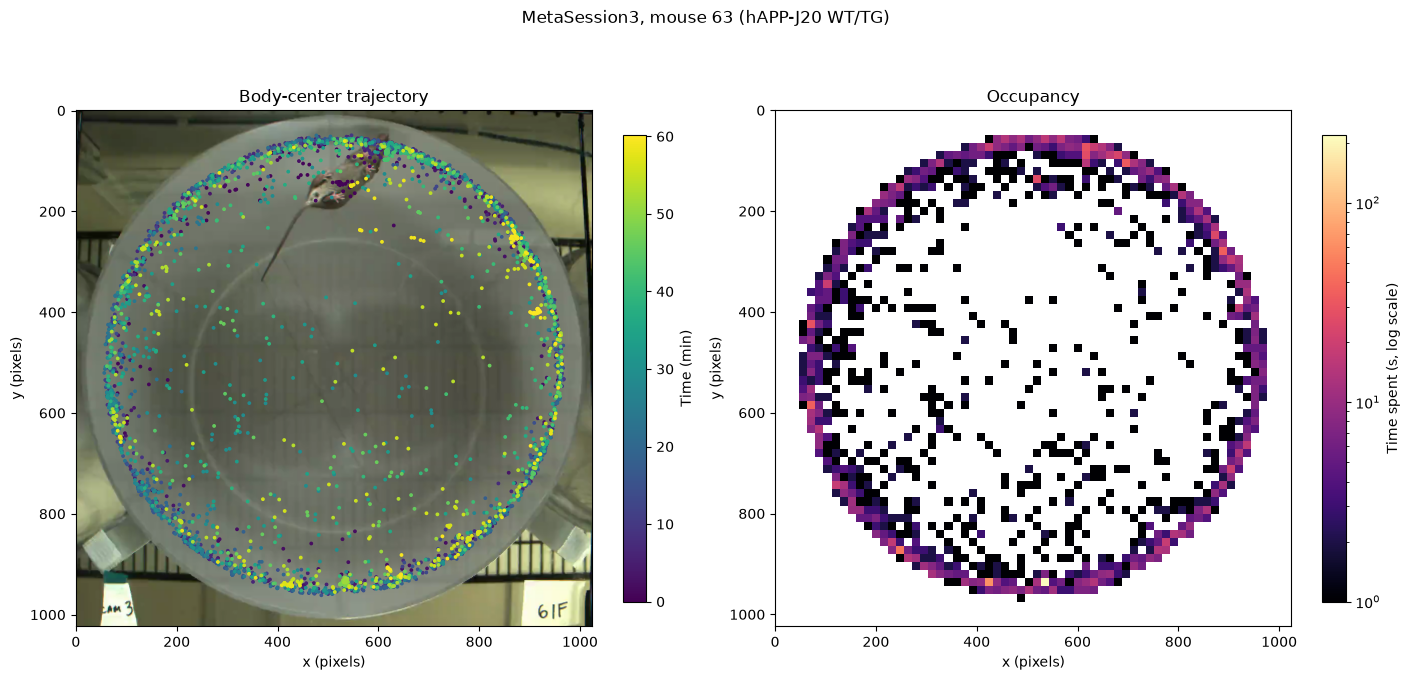

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7), constrained_layout=True)

axes[0].imshow(background)
points = axes[0].scatter(position["x"], position["y"], c=position.index / 60, s=3, cmap="viridis")
fig.colorbar(points, ax=axes[0], shrink=0.7, label="Time (min)")
axes[0].set_title("Body-center trajectory")

height, width = background.shape[:2]
occupancy, _, _ = np.histogram2d(
    position["y"].dropna(), position["x"].dropna(), bins=64, range=[[0, height], [0, width]]
)
image = axes[1].imshow(
    np.ma.masked_equal(occupancy, 0), extent=[0, width, height, 0], cmap="magma", norm=LogNorm()
)
fig.colorbar(image, ax=axes[1], shrink=0.7, label="Time spent (s, log scale)")
axes[1].set_title("Occupancy")

for ax in axes:
    ax.set_xlabel("x (pixels)")
    ax.set_ylabel("y (pixels)")
fig.suptitle(f"{nwbfile.session_id}, mouse {subject.subject_id} ({subject.genotype})")
plt.show()

## Distance traveled over the session

Distance is the sum of the steps between consecutive 1-second positions, in pixels. The arena was not
calibrated, so distances are in pixels and can differ slightly between cameras. The videos run a few
seconds past 60 minutes, so the last, partial minute is left out of the plot.

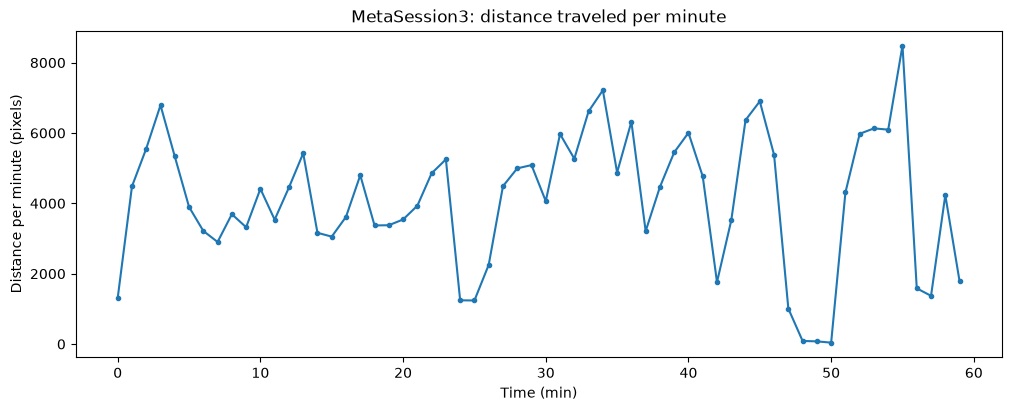

In [8]:
def get_distance_per_bin(position: pd.DataFrame, bin_size: float = 60.0) -> pd.Series:
    steps = np.hypot(position["x"].diff(), position["y"].diff())
    return steps.groupby((steps.index // bin_size) * bin_size).sum()


distance_per_minute = get_distance_per_bin(position).loc[: 59 * 60]

fig, ax = plt.subplots(figsize=(10, 4), constrained_layout=True)
ax.plot(distance_per_minute.index / 60, distance_per_minute.values, marker="o", markersize=3)
ax.set_xlabel("Time (min)")
ax.set_ylabel("Distance per minute (pixels)")
ax.set_title(f"{nwbfile.session_id}: distance traveled per minute")
plt.show()

In [9]:
io.close()

## All sessions: distance traveled by genotype and exposure

The same measure for every session. Exposure is the order of each mouse's sessions by start time.
Lines connect the two exposures of the same mouse.

In [10]:
rows = []
for file_path in sorted(nwb_dir_path.glob("*.nwb")):
    with NWBHDF5IO(file_path, "r") as session_io:
        session_nwbfile = session_io.read()
        rows.append(
            dict(
                session_id=session_nwbfile.session_id,
                subject_id=session_nwbfile.subject.subject_id,
                genotype=session_nwbfile.subject.genotype,
                sex=session_nwbfile.subject.sex,
                session_start_time=session_nwbfile.session_start_time,
                distance=get_distance_per_bin(get_body_center(session_nwbfile)).sum(),
            )
        )
sessions = pd.DataFrame(rows)
sessions["exposure"] = sessions.groupby("subject_id")["session_start_time"].rank().astype(int)
sessions.groupby(["genotype", "exposure"])["distance"].describe()[["count", "mean", "std"]].round(0)

count      mean       std
genotype       exposure                           
hAPP-J20 WT/TG 1          28.0  451671.0  149006.0
               2          28.0  383845.0  170441.0
hAPP-J20 WT/WT 1          27.0  226638.0   53514.0
               2          26.0  145546.0   52880.0

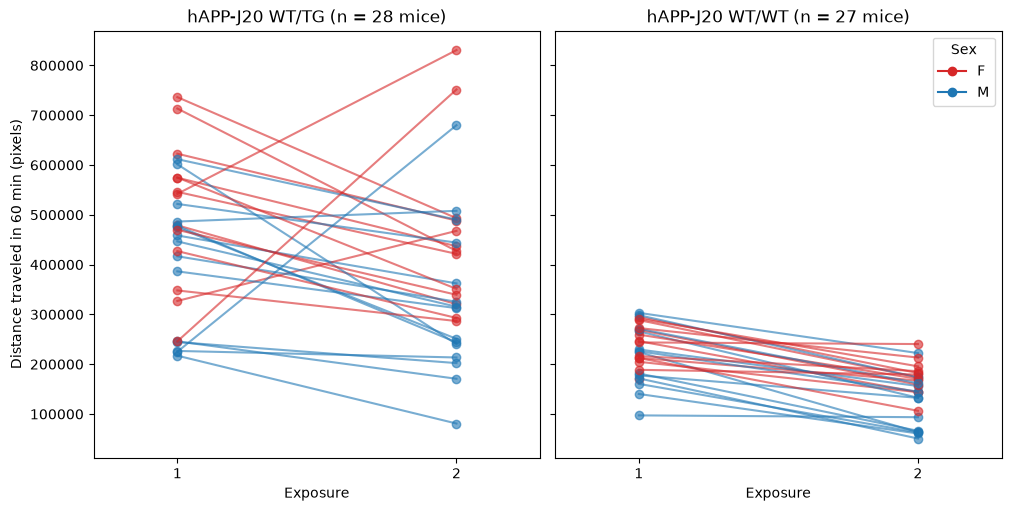

In [11]:
genotypes = sorted(sessions["genotype"].unique())
fig, axes = plt.subplots(1, len(genotypes), figsize=(10, 5), sharey=True, constrained_layout=True)
for ax, genotype in zip(axes, genotypes):
    for _, mouse_sessions in sessions[sessions["genotype"] == genotype].groupby("subject_id"):
        mouse_sessions = mouse_sessions.sort_values("exposure")
        color = "tab:red" if mouse_sessions["sex"].iloc[0] == "F" else "tab:blue"
        ax.plot(mouse_sessions["exposure"], mouse_sessions["distance"], marker="o", color=color, alpha=0.6)
    ax.set_xticks([1, 2])
    ax.set_xlim(0.7, 2.3)
    ax.set_xlabel("Exposure")
    ax.set_title(f"{genotype} (n = {sessions[sessions['genotype'] == genotype]['subject_id'].nunique()} mice)")
axes[0].set_ylabel("Distance traveled in 60 min (pixels)")
axes[-1].legend(
    handles=[plt.Line2D([], [], color="tab:red", marker="o", label="F"), plt.Line2D([], [], color="tab:blue", marker="o", label="M")],
    title="Sex",
)
plt.show()

## Summary

This notebook loaded one session, read its subject and session metadata, plotted the body-center
trajectory and occupancy from the DeepLabCut pose estimates, and computed distance traveled for every
session. The per-stream review notebooks show the video, pose estimates and training frames in detail.

Further resources:

- [PyNWB documentation](https://pynwb.readthedocs.io/)
- [ndx-pose](https://github.com/rly/ndx-pose)
- [NWB overview](https://nwb-overview.readthedocs.io/)